# Notebook 07 — Optimization, Regularization, and Custom Training

**Level:** Intermediate  
**Track:** Deep Learning with TensorFlow  
**Main tools:** TensorFlow, Keras, NumPy, Pandas, Matplotlib, and scikit-learn  
**Focus:** How neural networks learn, how optimization algorithms update parameters, and how regularization improves generalization.

This chapter connects the mathematics of gradients to practical neural-network training. You will derive a small backpropagation example, compare optimizers and learning rates, diagnose underfitting and overfitting, apply regularization methods, and implement a custom training loop with `tf.GradientTape`.

> **Important:** The dataset used in the practical experiments is synthetic and is intended only for education. It does not represent real biological, clinical, or scientific measurements. Performance on synthetic data does not establish real-world validity.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Explain the role of an objective function, gradients, and parameter updates in neural-network training.
2. Derive gradients for a small neural network using the chain rule.
3. Distinguish batch, stochastic, and mini-batch gradient descent.
4. Explain and compare SGD, Momentum, RMSprop, Adam, and AdamW.
5. Diagnose learning-rate problems and use learning-rate schedules.
6. Explain why initialization affects gradient flow and training stability.
7. Recognize underfitting, overfitting, and the bias–variance trade-off.
8. Apply L1/L2 regularization, dropout, batch normalization, and early stopping appropriately.
9. Use model checkpointing, gradient clipping, and TensorBoard for more reliable training.
10. Implement a custom training and validation loop using `tf.GradientTape`.
11. Compare model variants using validation data and reserve the test set for final evaluation.

## Notebook Roadmap

| Section | Topic |
|---:|---|
| 0 | Environment setup and reproducibility |
| 1 | The optimization problem and computational graphs |
| 2 | Backpropagation: a worked mathematical example |
| 3 | Gradient descent and batch strategies |
| 4 | SGD, Momentum, RMSprop, Adam, and AdamW |
| 5 | Learning rates and learning-rate schedules |
| 6 | Weight initialization and gradient flow |
| 7 | Build a controlled regression dataset |
| 8 | Diagnose underfitting and overfitting |
| 9 | Regularization: L1, L2, dropout, and batch normalization |
| 10 | Early stopping, checkpoints, and TensorBoard |
| 11 | Gradient clipping and numerical stability |
| 12 | Custom training loop with `tf.GradientTape` |
| 13 | Controlled regularization experiment and model comparison |
| 14 | Common mistakes, exercises, and references |

Run the notebook from top to bottom. Use the validation set for all model-selection decisions. The test set is reserved for the final evaluation after the training strategy has been selected.

## 0. Environment Setup and Reproducibility

The notebook uses TensorFlow through its Keras API. A CPU is sufficient for the small synthetic dataset. Set random seeds before constructing models and datasets. Seeds improve reproducibility, but exact bitwise identity is not guaranteed across devices, library builds, or parallel execution paths.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", getattr(keras, "__version__", "Bundled with TensorFlow"))
print("NumPy:", np.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow: 2.21.0
Keras: 3.15.1
NumPy: 2.4.6
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### 0.1 Reproducibility Checklist

- Set Python and NumPy random seeds where relevant.
- Set the TensorFlow/Keras seed before model creation.
- Keep the data split fixed when comparing training strategies.
- Fit preprocessing transformations on the training subset only.
- Record the optimizer, learning rate, batch size, architecture, and callbacks.
- Do not select hyperparameters using the test set.

For a formal project, also record package versions, hardware, data provenance, and the exact configuration used for each run.

In [2]:
import platform

print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("TensorFlow build info:", tf.sysconfig.get_build_info())

Python: 3.11.0
Platform: Windows-10-10.0.19045-SP0
TensorFlow build info: OrderedDict([('is_cuda_build', False), ('is_rocm_build', False), ('is_tensorrt_build', False), ('msvcp_dll_names', 'msvcp140.dll,msvcp140_1.dll')])


## 1. The Optimization Problem

### 1.1 A Neural Network as a Parameterized Function

A neural network maps an input vector to a prediction. Its trainable parameters are collected into a parameter set, commonly written as $\theta$.

For a dataset containing $N$ observations, a typical empirical objective is:

$$
J(\theta) = \frac{1}{N}\sum_{i=1}^{N} \mathcal{L}(f_{\theta}(x_i), y_i)
$$

where:

- $f_{\theta}(x_i)$ is the model prediction for observation $i$.
- $y_i$ is its target.
- $\mathcal{L}$ is the per-observation loss function.
- $J(\theta)$ is the average training objective.

Training attempts to find parameters that make the objective small while preserving performance on unseen data. The optimizer is the algorithm that determines how parameter values are updated.

### 1.2 The Gradient

For a scalar objective and parameter vector $\theta$, the gradient is the vector of partial derivatives:

$$
\nabla_{\theta} J(\theta) = \begin{bmatrix}
\frac{\partial J}{\partial \theta_1} \\ \vdots \\ \frac{\partial J}{\partial \theta_p}
\end{bmatrix}
$$

The gradient points in the direction of steepest local increase. To decrease the objective, gradient descent moves in the opposite direction.

A basic gradient-descent update is:

$$
\theta_{t+1} = \theta_t - \eta \, \nabla_{\theta}J(\theta_t)
$$

Here, $\eta$ is the **learning rate**. It controls the size of each update and strongly affects training stability and speed.

In [3]:
# A one-dimensional objective makes the direction of the gradient easy to inspect.
def objective(w):
    return (w - 3.0) ** 2

def derivative(w):
    return 2.0 * (w - 3.0)

for w in [-1.0, 1.0, 3.0, 5.0]:
    print(f"w={w:>4.1f} | J(w)={objective(w):>5.2f} | dJ/dw={derivative(w):>5.2f}")

w=-1.0 | J(w)=16.00 | dJ/dw=-8.00
w= 1.0 | J(w)= 4.00 | dJ/dw=-4.00
w= 3.0 | J(w)= 0.00 | dJ/dw= 0.00
w= 5.0 | J(w)= 4.00 | dJ/dw= 4.00


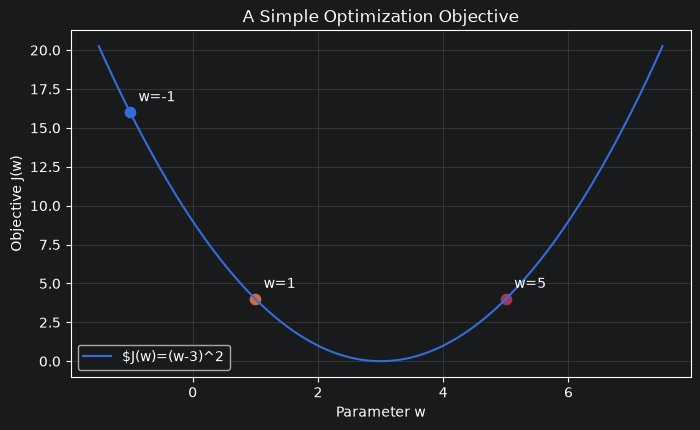

In [4]:
w_grid = np.linspace(-1.5, 7.5, 300)
plt.figure(figsize=(8, 4.5))
plt.plot(w_grid, objective(w_grid), label=r"$J(w)=(w-3)^2")
for w in [-1.0, 1.0, 5.0]:
    plt.scatter(w, objective(w), s=55)
    plt.annotate(f"w={w:g}", (w, objective(w)), xytext=(6, 8), textcoords="offset points")
plt.xlabel("Parameter w")
plt.ylabel("Objective J(w)")
plt.title("A Simple Optimization Objective")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 1.3 Computational Graphs and the Chain Rule

A neural network is a composition of operations. A computational graph records how intermediate quantities depend on earlier quantities. Backpropagation applies the chain rule to compute how the final loss changes with respect to every trainable parameter.

For a composition $L = f(g(h(x)))$, the chain rule gives:

$$
\frac{dL}{dx} = \frac{dL}{df}\frac{df}{dg}\frac{dg}{dh}\frac{dh}{dx}
$$

The same principle applies to neural networks with many layers. The gradient is propagated backward from the loss toward earlier layers.

In [5]:
# A small scalar computational graph: u = x*w1, h = tanh(u), y_hat = h*w2.
# The code below computes the forward values; gradients are derived in the next section.
x_demo, w1_demo, w2_demo = 1.5, 0.8, -0.6
u_demo = x_demo * w1_demo
h_demo = np.tanh(u_demo)
y_hat_demo = h_demo * w2_demo
print({"u": u_demo, "hidden_activation": h_demo, "prediction": y_hat_demo})

{'u': 1.2000000000000002, 'hidden_activation': np.float64(0.8336546070121553), 'prediction': np.float64(-0.5001927642072932)}


## 2. Backpropagation: A Worked Mathematical Example

Consider a tiny network with one scalar input, one hidden unit using `tanh`, and one linear output:

$$
z_1 = w_1x + b_1, \qquad h = \tanh(z_1)
$$

$$
\hat{y} = w_2h + b_2, \qquad L = \frac{1}{2}(\hat{y}-y)^2
$$

Define the output error as $\delta_2 = \hat{y}-y$. Since the derivative of $\tanh(z)$ is $1-\tanh^2(z)$, the hidden-layer error is:

$$
\delta_1 = \delta_2 w_2 (1-h^2)
$$

The parameter gradients are:

$$
\frac{\partial L}{\partial w_2}=\delta_2 h, \qquad \frac{\partial L}{\partial b_2}=\delta_2
$$

$$
\frac{\partial L}{\partial w_1}=\delta_1 x, \qquad \frac{\partial L}{\partial b_1}=\delta_1
$$

This is a one-hidden-unit example. Larger networks apply the same chain-rule logic to vector and matrix operations.

In [6]:
def forward_and_loss(params, x, target):
    w1, b1, w2, b2 = params
    z1 = w1 * x + b1
    h = np.tanh(z1)
    prediction = w2 * h + b2
    loss = 0.5 * (prediction - target) ** 2
    return loss, (z1, h, prediction)

def analytic_gradients(params, x, target):
    w1, b1, w2, b2 = params
    loss, (z1, h, prediction) = forward_and_loss(params, x, target)
    delta2 = prediction - target
    delta1 = delta2 * w2 * (1.0 - h**2)
    return np.array([delta1 * x, delta1, delta2 * h, delta2], dtype=float)

def finite_difference_gradients(params, x, target, epsilon=1e-6):
    params = np.asarray(params, dtype=float)
    numerical = np.zeros_like(params)
    for index in range(len(params)):
        plus = params.copy()
        minus = params.copy()
        plus[index] += epsilon
        minus[index] -= epsilon
        numerical[index] = (
            forward_and_loss(plus, x, target)[0]
            - forward_and_loss(minus, x, target)[0]
        ) / (2.0 * epsilon)
    return numerical

params_demo = np.array([0.7, -0.1, 0.9, 0.2])
x_demo, target_demo = 1.2, -0.4
analytic = analytic_gradients(params_demo, x_demo, target_demo)
numerical = finite_difference_gradients(params_demo, x_demo, target_demo)

print("Analytic gradients:  ", np.round(analytic, 8))
print("Numerical gradients: ", np.round(numerical, 8))
print("Maximum absolute difference:", np.max(np.abs(analytic - numerical)))

Analytic gradients:   [0.76097771 0.63414809 0.73372837 1.16623065]
Numerical gradients:  [0.76097771 0.63414809 0.73372837 1.16623065]
Maximum absolute difference: 1.7977730415452697e-10


### 2.1 Why Gradient Checking Matters

A numerical gradient approximates a derivative using small perturbations of one parameter at a time. It is useful for checking a manually derived gradient on a tiny model.

$$
\frac{\partial J}{\partial \theta_j} \approx \frac{J(\theta_j+\epsilon)-J(\theta_j-\epsilon)}{2\epsilon}
$$

Gradient checking is computationally expensive for large neural networks, so it is mainly a debugging tool for small custom operations or custom layers. Automatic differentiation should be used for normal TensorFlow training.

In [7]:
assert np.allclose(analytic, numerical, rtol=1e-5, atol=1e-7), "Gradient check did not pass."
print("Gradient check passed.")

Gradient check passed.


### 2.2 Backpropagation in TensorFlow

`tf.GradientTape` records operations executed inside its context and can differentiate a scalar loss with respect to watched tensors or trainable variables. Keras uses automatic differentiation in its standard training workflow. You will use `GradientTape` explicitly in Section 12.

In [8]:
# A minimal automatic-differentiation example.
w = tf.Variable(2.0)
with tf.GradientTape() as tape:
    loss_value = (w - 3.0) ** 2
gradient_value = tape.gradient(loss_value, w)
print("Loss:", float(loss_value.numpy()))
print("Gradient:", float(gradient_value.numpy()))

Loss: 1.0
Gradient: -2.0


## 3. Gradient Descent and Batch Strategies

### 3.1 Batch Gradient Descent

Batch gradient descent computes the gradient using the entire training dataset before each update. It gives a stable estimate of the full-dataset gradient, but each update can be expensive for large datasets.

### 3.2 Stochastic Gradient Descent

Stochastic gradient descent updates parameters using one observation at a time. Updates are inexpensive but noisy. The noise can sometimes help the optimizer move through flat or irregular regions, but it can also make convergence less stable.

### 3.3 Mini-Batch Gradient Descent

Mini-batch gradient descent uses a subset of observations per update. It is the common practical choice because it balances computation, gradient noise, and hardware utilization.

For a batch $B_t$:

$$
\theta_{t+1} = \theta_t - \eta \, \frac{1}{|B_t|}\sum_{i\in B_t}\nabla_{\theta}\mathcal{L}_i(\theta_t)
$$

The batch size affects the number of updates per epoch, memory use, and the noise of the gradient estimate.

In [9]:
# Demonstrate batch construction and the number of updates per epoch.
n_samples = 1_000
for batch_size in [1, 16, 32, 128, 1_000]:
    n_updates = int(np.ceil(n_samples / batch_size))
    print(f"batch_size={batch_size:>4} -> updates per epoch={n_updates:>4}")

batch_size=   1 -> updates per epoch=1000
batch_size=  16 -> updates per epoch=  63
batch_size=  32 -> updates per epoch=  32
batch_size= 128 -> updates per epoch=   8
batch_size=1000 -> updates per epoch=   1


### 3.4 A One-Parameter Mini-Batch Illustration

The next example uses a linear model and a small synthetic dataset to show why gradients from different mini-batches are not identical. This is a conceptual illustration rather than a substitute for Keras training.

In [10]:
rng = np.random.default_rng(SEED)
x_linear = rng.normal(size=(96, 1))
y_linear = 2.5 * x_linear[:, 0] - 0.8 + rng.normal(0, 0.5, size=96)

w_start, b_start = 0.0, 0.0

def linear_batch_gradient(x_batch, y_batch, w, b):
    prediction = w * x_batch[:, 0] + b
    error = prediction - y_batch
    dw = np.mean(2.0 * error * x_batch[:, 0])
    db = np.mean(2.0 * error)
    return np.array([dw, db])

full_gradient = linear_batch_gradient(x_linear, y_linear, w_start, b_start)
mini_gradients = []
for start in range(0, len(x_linear), 16):
    mini_gradients.append(
        linear_batch_gradient(
            x_linear[start:start + 16], y_linear[start:start + 16], w_start, b_start
        )
    )
mini_gradients = np.asarray(mini_gradients)

print("Full-batch gradient:", np.round(full_gradient, 3))
print("Mini-batch gradients:\n", np.round(mini_gradients, 3))
print("Mean mini-batch gradient:", np.round(mini_gradients.mean(axis=0), 3))

Full-batch gradient: [-2.927  1.746]
Mini-batch gradients:
 [[-3.774  2.141]
 [-3.229  0.537]
 [-1.786  1.219]
 [-3.493  2.15 ]
 [-2.204  1.93 ]
 [-3.072  2.501]]
Mean mini-batch gradient: [-2.927  1.746]


## 4. Optimization Algorithms

Different optimizers use different histories of past gradients to determine update direction and magnitude.

### 4.1 Stochastic Gradient Descent (SGD)

$$
\theta_t = \theta_{t-1} - \eta g_t
$$

SGD is simple and can generalize well when tuned carefully. It may require a suitable learning-rate schedule and can converge slowly when the objective has directions with very different curvature.

### 4.2 Momentum

Momentum accumulates a moving direction from past gradients. One common convention is:

$$
v_t = \beta v_{t-1} + g_t, \qquad \theta_t = \theta_{t-1} - \eta v_t
$$

The momentum coefficient $\beta$ controls how strongly previous updates influence the current update. Implementations may use slightly different scaling conventions.

### 4.3 RMSprop

RMSprop maintains an exponential moving average of squared gradients:

$$
s_t = \rho s_{t-1} + (1-\rho)g_t^2
$$

A parameter-wise scaled update is then:

$$
\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{s_t}+\epsilon}g_t
$$

This scaling can reduce sensitivity to differences in gradient magnitudes across parameters.

### 4.4 Adam

Adam combines moving averages of gradients and squared gradients:

$$
m_t = \beta_1m_{t-1}+(1-\beta_1)g_t
$$

$$
v_t = \beta_2v_{t-1}+(1-\beta_2)g_t^2
$$

It applies bias corrections and uses the corrected moments to scale the update. Adam is a widely used adaptive optimizer and is often a strong starting point, but it is not guaranteed to be best for every task.

### 4.5 AdamW and Weight Decay

AdamW applies weight decay separately from Adam's adaptive gradient update. This is not exactly the same as adding an L2 penalty to the loss when using an adaptive optimizer.

A simplified conceptual update is:

$$
\theta_t = \theta_{t-1} - \eta\,\text{AdamUpdate}(g_t) - \eta\lambda\theta_{t-1}
$$

The implementation details of an optimizer matter. In Keras, `keras.optimizers.AdamW` exposes a `weight_decay` argument. Use the official API documentation for the exact supported options in your installed version.

In [11]:
optimizer_examples = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "SGD with Momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": keras.optimizers.Adam(learning_rate=0.001),
    "AdamW": keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
}
for name, optimizer in optimizer_examples.items():
    print(f"{name:>20}: {optimizer.__class__.__name__}")

                 SGD: SGD
   SGD with Momentum: SGD
             RMSprop: RMSprop
                Adam: Adam
               AdamW: AdamW


### 4.6 What Should You Choose?

| Optimizer | Main idea | Practical notes |
|---|---|---|
| SGD | Uses current gradient | Often benefits from careful learning-rate scheduling |
| SGD + Momentum | Accumulates update direction | Can accelerate progress in consistent directions |
| RMSprop | Scales by moving average of squared gradients | Useful adaptive method; tune its learning rate |
| Adam | Adaptive first and second moments | Convenient strong baseline for many tasks |
| AdamW | Adam with decoupled weight decay | Useful when weight decay is part of the regularization strategy |

Do not compare optimizers using only one run with unrelated initial weights. For a fairer comparison, keep the data split, model architecture, training budget, initialization strategy, and evaluation protocol consistent. Repeat experiments with multiple seeds for stronger evidence.

## 5. Learning Rates and Learning-Rate Schedules

### 5.1 Learning Rate Too Small or Too Large

- **Too small:** optimization may progress very slowly and appear stalled within the available training budget.
- **Too large:** updates may overshoot useful regions, oscillate, or diverge.
- **Appropriate:** training makes stable progress and validation performance improves without severe instability.

The best learning rate depends on the model, loss scale, optimizer, batch size, initialization, and data.

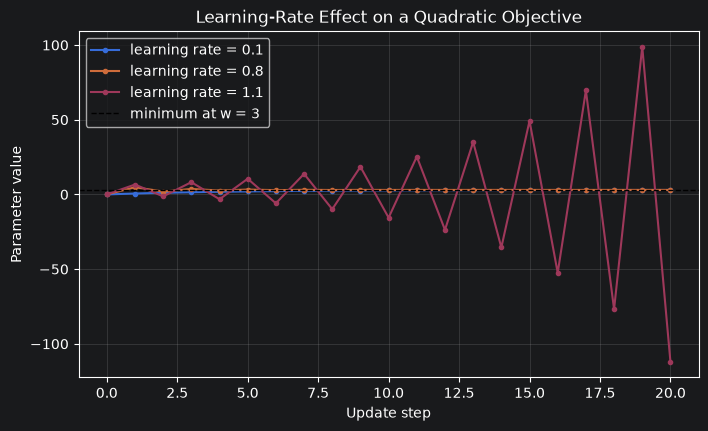

In [12]:
def gradient_descent_trajectory(learning_rate, start=0.0, steps=20):
    values = [start]
    current = start
    for _ in range(steps):
        current = current - learning_rate * 2.0 * (current - 3.0)
        values.append(current)
    return np.asarray(values)

learning_rates = [0.1, 0.8, 1.1]
plt.figure(figsize=(8, 4.5))
for lr in learning_rates:
    trajectory = gradient_descent_trajectory(lr)
    plt.plot(trajectory, marker="o", markersize=3, label=f"learning rate = {lr}")
plt.axhline(3.0, linestyle="--", color="black", linewidth=1, label="minimum at w = 3")
plt.xlabel("Update step")
plt.ylabel("Parameter value")
plt.title("Learning-Rate Effect on a Quadratic Objective")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 5.2 Exponential Decay

An exponential schedule gradually reduces the learning rate as training proceeds:

$$
\eta_t = \eta_0 \gamma^{t/k}
$$

where $\eta_0$ is the initial learning rate, $\gamma$ is the decay factor, and $k$ controls the decay interval.

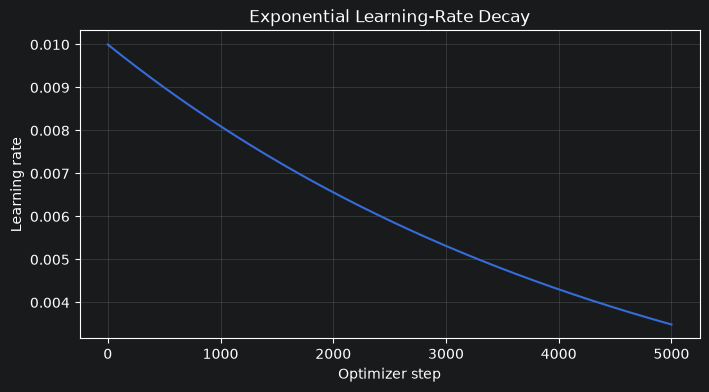

In [13]:
initial_learning_rate = 1e-2
schedule = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=initial_learning_rate,
    decay_steps=500,
    decay_rate=0.9,
    staircase=False,
)

steps = np.arange(0, 5_001)
learning_rate_values = [float(schedule(step).numpy()) for step in steps]
plt.figure(figsize=(8, 4))
plt.plot(steps, learning_rate_values)
plt.xlabel("Optimizer step")
plt.ylabel("Learning rate")
plt.title("Exponential Learning-Rate Decay")
plt.grid(alpha=0.25)
plt.show()

### 5.3 Common Keras Scheduling Options

Keras provides learning-rate schedules such as exponential decay and cosine decay. Callbacks such as `ReduceLROnPlateau` can reduce the learning rate when a monitored validation metric stops improving. A schedule is part of the optimizer configuration; a callback reacts to training observations.

In [14]:
cosine_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=2_000,
    alpha=0.1,
)

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=6,
    min_lr=1e-5,
    verbose=1,
)

print("Cosine schedule initial LR:", float(cosine_schedule(0).numpy()))
print("ReduceLROnPlateau callback:", reduce_lr_callback.__class__.__name__)

Cosine schedule initial LR: 0.0010000000474974513
ReduceLROnPlateau callback: ReduceLROnPlateau


## 6. Weight Initialization and Gradient Flow

### 6.1 Why Initialization Matters

Weights should begin with values that allow signals and gradients to propagate through the network. If activations or gradients become extremely small, early layers may learn very slowly. If they become extremely large, training can become unstable.

Common initializers include:

- **Glorot/Xavier:** designed to balance signal scale across layers under assumptions about activation and connectivity.
- **He:** commonly paired with ReLU-family activations.
- **LeCun:** often used with SELU-related setups.

These are useful starting points, not guarantees. Architecture, activation functions, normalization, and data still influence training behavior.

### 6.2 Initialization Heuristics

For a dense layer with fan-in $n_{in}$ and fan-out $n_{out}$, common variance scales include:

$$
\operatorname{Var}(W_{\text{Glorot}}) \approx \frac{2}{n_{in}+n_{out}}
$$

$$
\operatorname{Var}(W_{\text{He}}) \approx \frac{2}{n_{in}}
$$

The exact initializer distribution and scaling depend on the selected initializer implementation.

In [15]:
initializers_to_inspect = {
    "Glorot uniform": keras.initializers.GlorotUniform(seed=SEED),
    "He normal": keras.initializers.HeNormal(seed=SEED),
    "LeCun normal": keras.initializers.LecunNormal(seed=SEED),
}

for name, initializer in initializers_to_inspect.items():
    weights = initializer(shape=(128, 64)).numpy()
    print(
        f"{name:>15}: mean={weights.mean(): .4f}, "
        f"std={weights.std():.4f}, min={weights.min(): .4f}, max={weights.max(): .4f}"
    )

 Glorot uniform: mean= 0.0004, std=0.1017, min=-0.1767, max= 0.1768
      He normal: mean= 0.0003, std=0.1253, min=-0.2841, max= 0.2839
   LeCun normal: mean= 0.0002, std=0.0886, min=-0.2009, max= 0.2007


### 6.3 Vanishing and Exploding Gradients

Backpropagation repeatedly applies derivatives through the network. If many derivative factors have magnitudes below one, gradients can shrink as they travel backward. If many factors are large, gradients can grow rapidly.

This is one reason activation functions, initialization, normalization, residual connections, and gradient clipping matter. The following simplified demonstration multiplies repeated scalar factors; it illustrates the product effect but is not a full neural-network simulation.

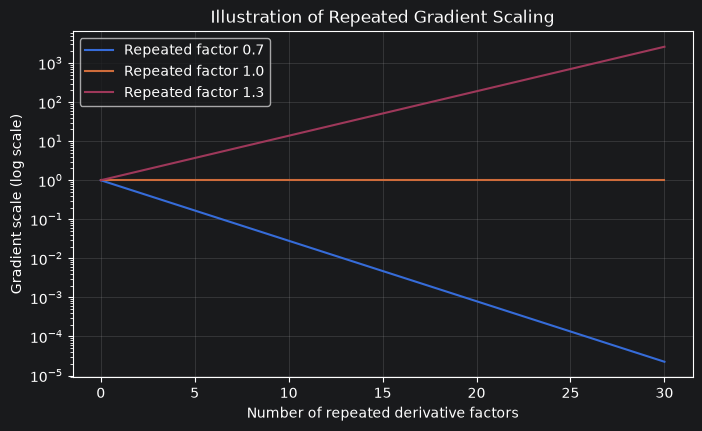

In [16]:
n_layers = 30
factor_cases = {
    "Repeated factor 0.7": 0.7,
    "Repeated factor 1.0": 1.0,
    "Repeated factor 1.3": 1.3,
}

plt.figure(figsize=(8, 4.5))
for label, factor in factor_cases.items():
    gradient_scale = np.array([factor ** depth for depth in range(n_layers + 1)])
    plt.plot(range(n_layers + 1), gradient_scale, label=label)
plt.yscale("log")
plt.xlabel("Number of repeated derivative factors")
plt.ylabel("Gradient scale (log scale)")
plt.title("Illustration of Repeated Gradient Scaling")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Create a Controlled Regression Dataset

The practical experiment uses a nonlinear target with noise and several irrelevant input features. A relatively high-capacity MLP can overfit this small dataset, making regularization strategies easier to study.

The dataset is synthetic. The feature names are generic and have no biological or clinical interpretation.

In [17]:
rng = np.random.default_rng(SEED)
N_SAMPLES = 720
N_FEATURES = 12

X_all = rng.normal(size=(N_SAMPLES, N_FEATURES)).astype(np.float32)
noise = rng.normal(0.0, 0.55, size=N_SAMPLES)
y_all = (
    1.8 * np.sin(1.4 * X_all[:, 0])
    + 0.75 * (X_all[:, 1] ** 2)
    - 1.1 * X_all[:, 2] * X_all[:, 3]
    + 0.65 * X_all[:, 4]
    - 0.45 * X_all[:, 5]
    + noise
).astype(np.float32)

feature_names = [f"feature_{i+1}" for i in range(N_FEATURES)]
dataset_df = pd.DataFrame(X_all, columns=feature_names)
dataset_df["target"] = y_all
print(dataset_df.head())
print("Dataset shape:", dataset_df.shape)

   feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  \
0   0.304717  -1.039984   0.750451   0.940565  -1.951035  -1.302179   
1   0.066031   1.127241   0.467509  -0.859292   0.368751  -0.958883   
2  -0.428328  -0.352134   0.532309   0.365444   0.412733   0.430821   
3  -0.113947  -0.840156  -0.824481   0.650593   0.743254   0.543154   
4   0.678914   0.067579   0.289119   0.631288  -1.457156  -0.319671   

   feature_7  feature_8  feature_9  feature_10  feature_11  feature_12  \
0   0.127840  -0.316243  -0.016801   -0.853044    0.879398    0.777792   
1   0.878450  -0.049926  -0.184862   -0.680930    1.222541   -0.154529   
2   2.141648  -0.406415  -0.512243   -0.813773    0.615979    1.128972   
3  -0.665510   0.232161   0.116686    0.218689    0.871429    0.223596   
4  -0.470373  -0.638878  -0.275142    1.494941   -0.865831    0.968278   

     target  
0  0.581526  
1  3.184661  
2 -1.383519  
3  0.062826  
4  0.738632  
Dataset shape: (720, 13)


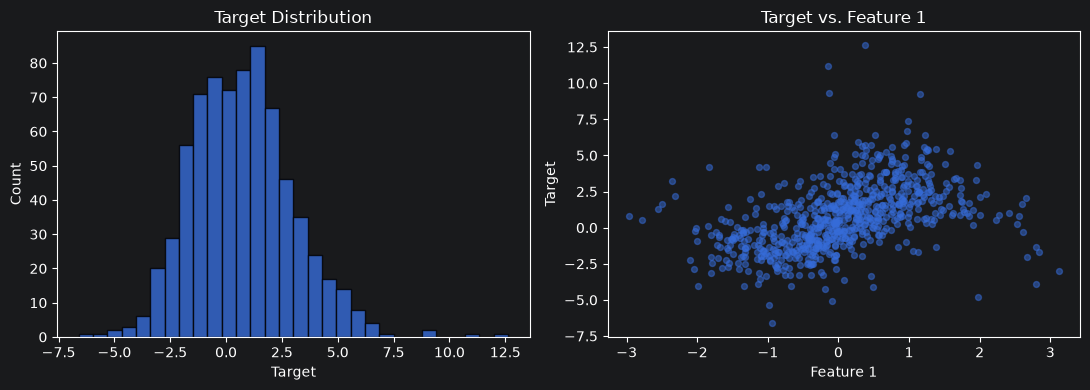

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(y_all, bins=30, edgecolor="black", alpha=0.8)
axes[0].set_title("Target Distribution")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Count")
axes[1].scatter(X_all[:, 0], y_all, alpha=0.5, s=18)
axes[1].set_title("Target vs. Feature 1")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Target")
plt.tight_layout()
plt.show()

### 7.1 Train, Validation, and Test Splits

Split the data before fitting the scaler. The training subset is used to estimate preprocessing parameters and update model weights. The validation subset is used to monitor training and select model settings. The test subset is held back for one final, unbiased evaluation under the chosen protocol.

$$
\text{Training data} \rightarrow \text{fit parameters and model}
$$

$$
\text{Validation data} \rightarrow \text{model selection and monitoring}
$$

$$
\text{Test data} \rightarrow \text{final evaluation only}
$$

In [19]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1765, random_state=SEED
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

# Keras regression outputs have shape (batch, 1); keep targets in the same shape.
y_train_2d = y_train.reshape(-1, 1).astype(np.float32)
y_val_2d = y_val.reshape(-1, 1).astype(np.float32)
y_test_2d = y_test.reshape(-1, 1).astype(np.float32)

print("Train:", X_train_scaled.shape, y_train_2d.shape)
print("Validation:", X_val_scaled.shape, y_val_2d.shape)
print("Test:", X_test_scaled.shape, y_test_2d.shape)

Train: (503, 12) (503, 1)
Validation: (109, 12) (109, 1)
Test: (108, 12) (108, 1)


### 7.2 Build `tf.data` Datasets

Mini-batches are created with `tf.data`. The training dataset is shuffled and batched; validation and test data are batched without shuffling. Prefetching can overlap input preparation with model execution.

In [20]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_scaled, y_train_2d))
    .shuffle(buffer_size=len(X_train_scaled), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_scaled, y_val_2d))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test_scaled, y_test_2d))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

for batch_x, batch_y in train_ds.take(1):
    print("Feature batch shape:", batch_x.shape)
    print("Target batch shape:", batch_y.shape)

Feature batch shape: (32, 12)
Target batch shape: (32, 1)


### 7.3 Empirical Optimizer Comparison

This comparison uses the same data split and a compact architecture for each optimizer. The learning rates are reasonable starting values, not a fully tuned comparison. For a rigorous benchmark, tune each optimizer on validation data and repeat with multiple seeds.


In [21]:
def build_optimizer_comparison_model():
    inputs = keras.Input(shape=(N_FEATURES,))
    x = layers.Dense(64, activation="relu", kernel_initializer="he_normal")(inputs)
    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(1)(x)
    return keras.Model(inputs, outputs)

optimizer_factories = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD + Momentum": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001),
    "AdamW": lambda: keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
}

optimizer_histories = {}
optimizer_models = {}
for optimizer_name, optimizer_factory in optimizer_factories.items():
    keras.utils.set_random_seed(SEED)
    comparison_model = build_optimizer_comparison_model()
    comparison_model.compile(
        optimizer=optimizer_factory(),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    comparison_history = comparison_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=45,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=8, restore_best_weights=True
            )
        ],
        verbose=0,
    )
    optimizer_histories[optimizer_name] = comparison_history.history
    optimizer_models[optimizer_name] = comparison_model
    print(
        f"{optimizer_name:>16}: best validation MSE = "
        f"{min(comparison_history.history['val_loss']):.4f}"
    )

optimizer_summary = pd.DataFrame([
    {
        "Optimizer": name,
        "Best validation MSE": min(history["val_loss"]),
        "Epochs": len(history["loss"]),
    }
    for name, history in optimizer_histories.items()
]).sort_values("Best validation MSE")
optimizer_summary


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


             SGD: best validation MSE = 2.1425
  SGD + Momentum: best validation MSE = 1.5640
         RMSprop: best validation MSE = 2.0579
            Adam: best validation MSE = 2.0813
           AdamW: best validation MSE = 2.1179


,Optimizer,Best validation MSE,Epochs
1,SGD + Momentum,1.564046,20
2,RMSprop,2.057860,45
3,Adam,2.081265,45
4,AdamW,2.117944,45
0,SGD,2.142473,41


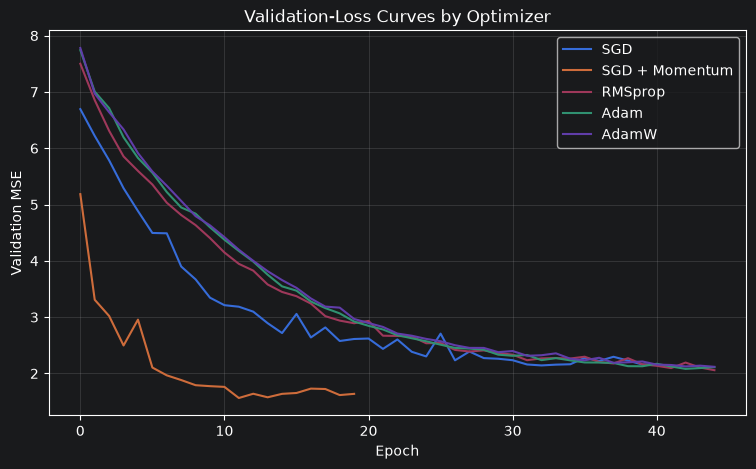

In [22]:
plt.figure(figsize=(9, 5))
for optimizer_name, history in optimizer_histories.items():
    plt.plot(history["val_loss"], label=optimizer_name)
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Validation-Loss Curves by Optimizer")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**Interpretation:** The lowest curve in this one run is not proof that an optimizer is universally superior. The comparison is influenced by learning-rate choices, initialization, early stopping, and random variation. Repeat with multiple seeds and tune each optimizer using validation data before drawing a strong conclusion.


## 8. Diagnose Underfitting and Overfitting

### 8.1 Definitions

- **Underfitting:** the model is too simple, poorly optimized, or insufficiently trained to capture the patterns in the training data. Training and validation errors both remain high.
- **Overfitting:** the model fits training-specific patterns, including noise, and performs worse on unseen data. Training error may continue decreasing while validation error stops improving or increases.
- **Good generalization:** training and validation performance are both useful and the gap between them is not excessive.

The bias–variance trade-off describes a broad tension: overly simple models may have high bias, while overly flexible models can have high variance. The best model is not necessarily the one with the lowest training loss.

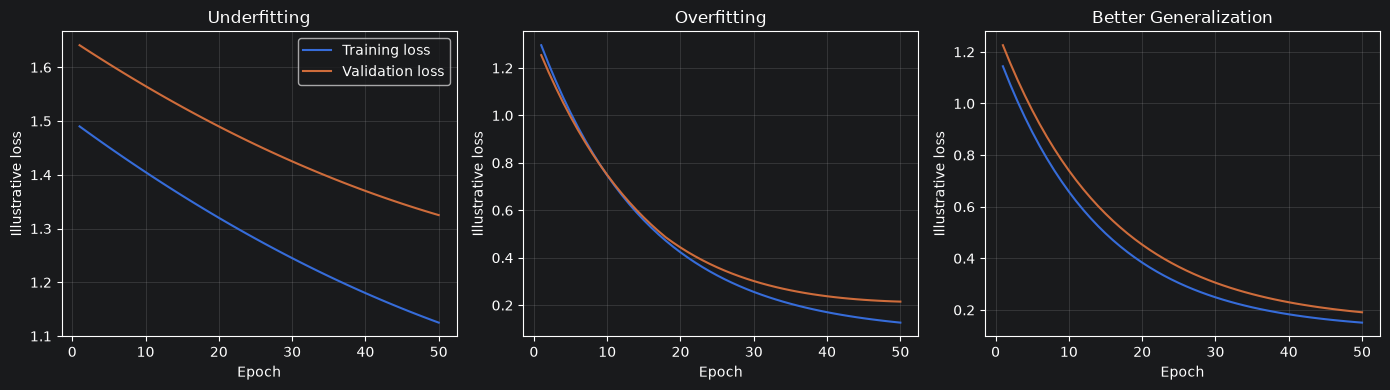

In [23]:
# A conceptual sketch of common training-curve patterns.
epoch_axis = np.arange(1, 51)
under_train = 1.5 - 0.010 * epoch_axis + 0.00005 * epoch_axis**2
under_val = 1.65 - 0.009 * epoch_axis + 0.00005 * epoch_axis**2
over_train = 1.3 * np.exp(-epoch_axis / 15) + 0.08
over_val = 1.25 * np.exp(-epoch_axis / 16) + 0.08 + 0.0025 * np.maximum(epoch_axis - 18, 0)
good_train = 1.1 * np.exp(-epoch_axis / 14) + 0.12
good_val = 1.15 * np.exp(-epoch_axis / 15) + 0.15

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, train_curve, val_curve, title in [
    (axes[0], under_train, under_val, "Underfitting"),
    (axes[1], over_train, over_val, "Overfitting"),
    (axes[2], good_train, good_val, "Better Generalization"),
]:
    ax.plot(epoch_axis, train_curve, label="Training loss")
    ax.plot(epoch_axis, val_curve, label="Validation loss")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Illustrative loss")
    ax.grid(alpha=0.25)
axes[0].legend()
plt.tight_layout()
plt.show()

### 8.2 Build a High-Capacity Baseline

First, build a relatively large network without explicit regularization. The purpose is to observe the effect of capacity and training duration, not to claim that this architecture is universally appropriate.

In [24]:
def build_mlp(units=(128, 128, 64), dropout_rate=0.0, l2_strength=0.0, batch_norm=False):
    inputs = keras.Input(shape=(N_FEATURES,), name="features")
    x = inputs
    for index, units_in_layer in enumerate(units, start=1):
        kernel_reg = regularizers.L2(l2_strength) if l2_strength > 0 else None
        x = layers.Dense(
            units_in_layer,
            kernel_initializer="he_normal",
            kernel_regularizer=kernel_reg,
            name=f"dense_{index}",
        )(x)
        if batch_norm:
            x = layers.BatchNormalization(name=f"batch_norm_{index}")(x)
        x = layers.Activation("relu", name=f"relu_{index}")(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate, name=f"dropout_{index}")(x)
    outputs = layers.Dense(1, name="regression_output")(x)
    return keras.Model(inputs, outputs)

baseline_model = build_mlp(units=(256, 128, 64))
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)
baseline_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regression_output (Dense)       │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,545 (174.00 KB)

 Trainable params: 44,545 (174.00 KB)

 Non-trainable params: 0 (0.00 B)

G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


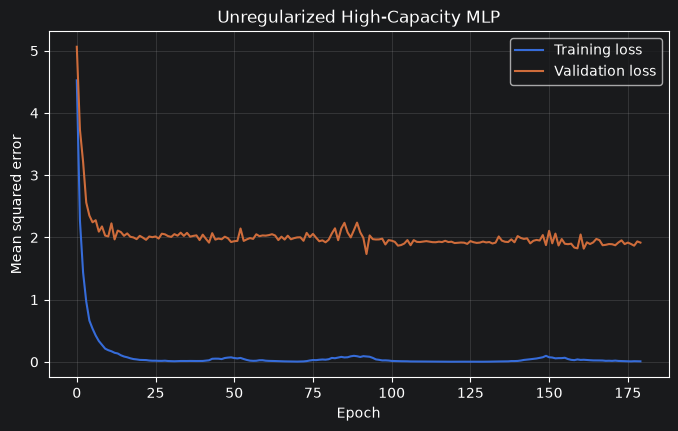

In [25]:
long_run_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=180,
    verbose=0,
)

plt.figure(figsize=(8, 4.5))
plt.plot(long_run_history.history["loss"], label="Training loss")
plt.plot(long_run_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Unregularized High-Capacity MLP")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 8.3 Locate the Best Validation Epoch

The minimum validation loss indicates the epoch with the best observed validation performance in this run. It is not appropriate to choose the best epoch by inspecting the test loss.

In [26]:
train_loss_values = np.asarray(long_run_history.history["loss"])
val_loss_values = np.asarray(long_run_history.history["val_loss"])
best_epoch_unregularized = int(np.argmin(val_loss_values) + 1)
print("Best validation epoch:", best_epoch_unregularized)
print("Training loss at best epoch:", float(train_loss_values[best_epoch_unregularized - 1]))
print("Validation loss at best epoch:", float(val_loss_values[best_epoch_unregularized - 1]))
print("Final training loss:", float(train_loss_values[-1]))
print("Final validation loss:", float(val_loss_values[-1]))

Best validation epoch: 93
Training loss at best epoch: 0.08666607737541199
Validation loss at best epoch: 1.7330375909805298
Final training loss: 0.008291484788060188
Final validation loss: 1.9165433645248413


## 9. Regularization Methods

Regularization changes training to reduce reliance on overly complex or unstable parameter settings. It may increase training error while improving validation performance. The correct choice depends on the task and should be assessed on validation data.

### 9.1 L1 Regularization

L1 regularization adds the absolute values of weights to the objective:

$$
J_{L1}(\theta) = J(\theta) + \lambda\sum_j |\theta_j|
$$

It can encourage sparse parameter values. The absolute-value penalty is not differentiable at zero, but subgradient-based optimization handles this in practice.

### 9.2 L2 Regularization

L2 regularization adds the squared magnitude of weights to the objective:

$$
J_{L2}(\theta) = J(\theta) + \lambda\sum_j \theta_j^2
$$

It discourages large weights and often produces smoother parameter configurations. In Keras, `kernel_regularizer=keras.regularizers.L2(...)` adds a penalty to the model's loss terms.

In [27]:
example_weights = np.array([0.1, -0.5, 1.2, -2.0, 0.0])
regularization_strength = 0.05
l1_penalty = regularization_strength * np.sum(np.abs(example_weights))
l2_penalty = regularization_strength * np.sum(example_weights ** 2)
print("Weights:", example_weights)
print("L1 penalty:", l1_penalty)
print("L2 penalty:", l2_penalty)

Weights: [ 0.1 -0.5  1.2 -2.   0. ]
L1 penalty: 0.19
L2 penalty: 0.28500000000000003


### 9.2.1 Keras Regularizer Objects

Keras exposes `L1`, `L2`, and combined `L1L2` regularizers. They can be applied to a layer's kernel, bias, or activity where supported. The layer's penalty terms are exposed through `model.losses` after the model has been called.


In [28]:
l1_dense_example = layers.Dense(
    16,
    kernel_regularizer=regularizers.L1(1e-4),
)
l1_l2_dense_example = layers.Dense(
    16,
    kernel_regularizer=regularizers.L1L2(l1=1e-5, l2=1e-4),
)
print("L1 regularizer:", l1_dense_example.kernel_regularizer)
print("Combined L1/L2 regularizer:", l1_l2_dense_example.kernel_regularizer)


L1 regularizer: <keras.src.regularizers.regularizers.L1 object at 0x00000226188ECD90>
Combined L1/L2 regularizer: <keras.src.regularizers.regularizers.L1L2 object at 0x000002261A3A1C90>


### 9.3 Dropout

Dropout randomly masks a fraction of activations during training. It discourages units from depending too strongly on particular other units. During inference, dropout is disabled and the layer uses its inference behavior.

A dropout rate of $p$ is the fraction of input units that are set to zero during a training call. Larger rates remove more activations and can cause underfitting if used excessively.

In [29]:
# Inspect a Dropout layer's behavior in training and inference modes.
dropout_layer = layers.Dropout(0.5, seed=SEED)
example_activation = tf.ones((4, 10))
train_mode_output = dropout_layer(example_activation, training=True)
inference_mode_output = dropout_layer(example_activation, training=False)
print("Training-mode output:\n", train_mode_output.numpy())
print("Inference-mode output:\n", inference_mode_output.numpy())

Training-mode output:
 [[0. 0. 2. 0. 0. 2. 2. 0. 0. 0.]
 [2. 0. 0. 0. 2. 2. 2. 0. 2. 0.]
 [0. 0. 0. 2. 2. 2. 0. 2. 0. 2.]
 [0. 2. 2. 2. 0. 2. 2. 2. 2. 0.]]
Inference-mode output:
 [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]


### 9.4 Batch Normalization

Batch normalization normalizes layer activations using batch statistics during training and moving statistics during inference. It can improve optimization behavior in some settings, but it is not simply interchangeable with dropout or weight regularization.

A typical dense-block ordering is:

`Dense (without activation) -> BatchNormalization -> Activation -> Dropout`

Very small batches can produce noisy batch statistics. Always consider the batch size and the training/inference distinction when using batch normalization.

In [30]:
# A compact example showing the intended layer ordering.
inputs_demo = keras.Input(shape=(N_FEATURES,))
x_demo = layers.Dense(64, use_bias=False, kernel_initializer="he_normal")(inputs_demo)
x_demo = layers.BatchNormalization()(x_demo)
x_demo = layers.Activation("relu")(x_demo)
x_demo = layers.Dropout(0.2)(x_demo)
outputs_demo = layers.Dense(1)(x_demo)
regularized_block_demo = keras.Model(inputs_demo, outputs_demo)
regularized_block_demo.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 961 (3.75 KB)

 Non-trainable params: 128 (512.00 B)

### 9.5 L2 Regularization vs. Weight Decay

These ideas are related but should not be treated as identical in every optimizer configuration.

- **L2 regularization** adds a penalty term to the loss being differentiated.
- **Weight decay** directly shrinks parameters as part of the optimizer update.
- For plain SGD, common formulations can be closely related under particular conventions.
- For adaptive optimizers, decoupled weight decay (as in AdamW) is not generally identical to adding an L2 penalty to the loss.

Choose the method intentionally and report its coefficient. Do not apply both strong L2 and strong weight decay without a reason, because their combined effect may over-regularize the model.

### 9.6 Regularization Strength

The regularization coefficient controls the contribution of the penalty. Too little may not reduce overfitting; too much can suppress useful model capacity and cause underfitting. Tune it using validation data rather than the test set.

In [31]:
regularization_grid = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]
print("Candidate L2 strengths:", regularization_grid)

Candidate L2 strengths: [0.0, 1e-05, 0.0001, 0.001, 0.01]


## 10. Early Stopping, Checkpointing, and TensorBoard

### 10.1 Early Stopping

Early stopping monitors a validation metric and stops training when it has failed to improve for a specified number of epochs. With `restore_best_weights=True`, Keras restores the model weights from the best monitored epoch.

Early stopping is a model-selection procedure. Its monitored dataset must be a validation set, not the test set.

In [32]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    min_delta=1e-4,
    restore_best_weights=True,
    verbose=1,
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=6,
    min_lr=1e-5,
    verbose=1,
)

print("Callbacks configured:", early_stopping.__class__.__name__, reduce_lr.__class__.__name__)

Callbacks configured: EarlyStopping ReduceLROnPlateau


### 10.2 Model Checkpointing

A checkpoint saves model state during training. A best-only checkpoint can preserve the model associated with the lowest monitored validation loss.

The native Keras model format uses the `.keras` extension. Use a location that is writable in your environment, and do not overwrite a valuable model artifact without keeping a backup.

In [33]:
ARTIFACT_DIR = Path("artifacts_notebook07")
ARTIFACT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = ARTIFACT_DIR / "best_regularized_model.keras"

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_PATH),
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1,
)
print("Checkpoint path:", CHECKPOINT_PATH.resolve())

Checkpoint path: C:\Users\mobin\Desktop\Deep-Learning-with-TensorFlow\notebooks\07-optimization-regularization\artifacts_notebook07\best_regularized_model.keras


### 10.3 Train with Early Stopping and Checkpointing

The next run uses moderate capacity and several regularization options. The exact best epoch and numerical loss values depend on the installed library versions and execution environment.

In [34]:
keras.utils.set_random_seed(SEED)
regularized_model = build_mlp(
    units=(128, 64),
    dropout_rate=0.20,
    l2_strength=1e-4,
    batch_norm=True,
)
regularized_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

regularized_history = regularized_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=150,
    callbacks=[early_stopping, reduce_lr, checkpoint_callback],
    verbose=0,
)

print("Epochs executed:", len(regularized_history.history["loss"]))
print("Best validation loss:", min(regularized_history.history["val_loss"]))

G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



Epoch 1: val_loss improved from None to 7.05768, saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 1: finished saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 2: val_loss improved from 7.05768 to 5.56968, saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 2: finished saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 3: val_loss improved from 5.56968 to 5.01357, saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 3: finished saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 4: val_loss improved from 5.01357 to 4.65002, saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 4: finished saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 5: val_loss improved from 4.65002 to 4.43436, saving model to artifacts_notebook07\best_regularized_model.keras

Epoch 5: finished saving model to artifacts_notebook07\best_regular

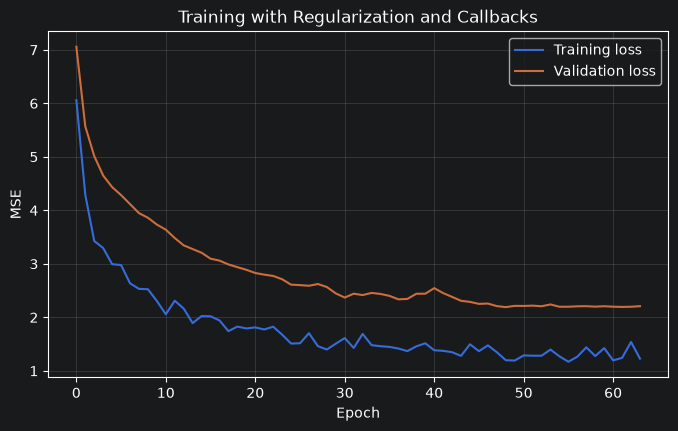

In [35]:
plt.figure(figsize=(8, 4.5))
plt.plot(regularized_history.history["loss"], label="Training loss")
plt.plot(regularized_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training with Regularization and Callbacks")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 10.4 Load the Best Checkpoint

If the checkpoint file exists, load it and verify that it can be used for inference. This is an important part of a reproducible model workflow.

In [36]:
if CHECKPOINT_PATH.exists():
    best_checkpoint_model = keras.models.load_model(CHECKPOINT_PATH)
    checkpoint_predictions = best_checkpoint_model.predict(X_val_scaled[:5], verbose=0)
    print("Loaded checkpoint successfully.")
    print("Predictions shape:", checkpoint_predictions.shape)
else:
    print("Checkpoint file was not created. Run the training cell above first.")

Loaded checkpoint successfully.
Predictions shape: (5, 1)


### 10.5 TensorBoard

TensorBoard can display training curves, learning rates, graph information, and other logged data. The Keras `TensorBoard` callback writes logs during training.

In [37]:
TENSORBOARD_LOG_DIR = Path("logs_notebook07") / "fit"
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=str(TENSORBOARD_LOG_DIR),
    histogram_freq=0,
    write_graph=True,
    update_freq="epoch",
)
print("TensorBoard log directory:", TENSORBOARD_LOG_DIR.resolve())

TensorBoard log directory: C:\Users\mobin\Desktop\Deep-Learning-with-TensorFlow\notebooks\07-optimization-regularization\logs_notebook07\fit


To record logs, pass `tensorboard_callback` to `model.fit()` along with the other callbacks. Then run the following command in a terminal from the project directory:

```bash
tensorboard --logdir logs_notebook07
```

Open the local address printed by TensorBoard in your browser. TensorBoard is a separate package in some TensorFlow installations; install it explicitly if the command is unavailable.

In [38]:
tensorboard_model = build_mlp(units=(64, 32))
tensorboard_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)
tensorboard_history = tensorboard_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[tensorboard_callback],
    verbose=0,
)
print("TensorBoard callback ran for", len(tensorboard_history.history["loss"]), "epochs")
print("Log directory:", TENSORBOARD_LOG_DIR.resolve())

G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


TensorBoard callback ran for 15 epochs
Log directory: C:\Users\mobin\Desktop\Deep-Learning-with-TensorFlow\notebooks\07-optimization-regularization\logs_notebook07\fit


## 11. Gradient Clipping and Numerical Stability

### 11.1 Why Clip Gradients?

When gradients become very large, parameter updates can become unstable. Gradient clipping limits the magnitude of gradients before the optimizer applies the update.

For global-norm clipping, if the gradient collection has norm greater than threshold $c$, all gradients are scaled by the same factor:

$$
g_i^{\text{clipped}} = g_i \cdot \min\left(1, \frac{c}{\|g\|_2}\right)
$$

Clipping can reduce the impact of unusually large gradients. It does not repair every cause of unstable training and should not replace appropriate initialization, data checks, or learning-rate selection.

In [39]:
gradients_example = [tf.constant([3.0, 4.0]), tf.constant([12.0])]
clipped_gradients, global_norm = tf.clip_by_global_norm(gradients_example, clip_norm=5.0)
clipped_norm = tf.linalg.global_norm(clipped_gradients)
print("Original global norm:", float(global_norm.numpy()))
print("Clipped global norm:", float(clipped_norm.numpy()))
print("Clipped gradients:", [g.numpy() for g in clipped_gradients])

Original global norm: 13.0
Clipped global norm: 5.0
Clipped gradients: [array([1.1538461, 1.5384616], dtype=float32), array([4.6153846], dtype=float32)]


### 11.2 Using Optimizer-Level Clipping

Keras optimizers expose gradient clipping options such as `clipnorm` and `global_clipnorm`. Check the installed optimizer API for supported arguments. Avoid clipping in multiple places unintentionally; choose one explicit strategy and document it.

In [40]:
clipped_optimizer = keras.optimizers.Adam(
    learning_rate=1e-3,
    global_clipnorm=1.0,
)
print("Optimizer global clip norm:", clipped_optimizer.global_clipnorm)

Optimizer global clip norm: 1.0


## 12. Custom Training Loop with `tf.GradientTape`

### 12.1 Why Write a Custom Loop?

`model.fit()` is the recommended starting point for most standard problems. A custom loop is useful when the training step needs specialized calculations, multiple losses, custom gradient handling, or non-standard update logic.

A standard custom training loop has three core steps:

1. Iterate over batches from a dataset.
2. Record the forward pass and loss with `tf.GradientTape`.
3. Compute gradients and update trainable variables with an optimizer.

When a model uses regularization layers, the extra terms in `model.losses` must be included in the total objective. This is an important difference from a simplistic custom loop that only computes the data loss.

### 12.2 Define the Model and Loss

This custom-loop example uses a compact MLP with L2 weight penalties and dropout. The training step adds the model's regularization losses to the data loss.

In [41]:
keras.utils.set_random_seed(SEED)
custom_model = build_mlp(
    units=(64, 32),
    dropout_rate=0.15,
    l2_strength=1e-4,
    batch_norm=False,
)
custom_optimizer = keras.optimizers.Adam(learning_rate=1e-3, global_clipnorm=1.0)
data_loss_fn = keras.losses.MeanSquaredError()

# Build model variables before tracing the custom step.
_ = custom_model(tf.zeros((1, N_FEATURES), dtype=tf.float32), training=False)
print("Trainable variables:", len(custom_model.trainable_variables))
print("Regularization losses:", len(custom_model.losses))

Trainable variables: 6
Regularization losses: 2


### 12.3 Define a Training Step

The `training=True` argument is essential for layers such as dropout and batch normalization. The validation step uses `training=False`, so dropout is disabled and batch-normalization moving statistics are used.

In [42]:
@tf.function
def custom_train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        predictions = custom_model(x_batch, training=True)
        data_loss = data_loss_fn(y_batch, predictions)
        if custom_model.losses:
            regularization_loss = tf.add_n(custom_model.losses)
        else:
            regularization_loss = tf.constant(0.0, dtype=data_loss.dtype)
        total_loss = data_loss + regularization_loss

    gradients = tape.gradient(total_loss, custom_model.trainable_variables)
    custom_optimizer.apply_gradients(zip(gradients, custom_model.trainable_variables))
    return total_loss, data_loss

@tf.function
def custom_validation_step(x_batch, y_batch):
    predictions = custom_model(x_batch, training=False)
    data_loss = data_loss_fn(y_batch, predictions)
    if custom_model.losses:
        regularization_loss = tf.add_n(custom_model.losses)
    else:
        regularization_loss = tf.constant(0.0, dtype=data_loss.dtype)
    return data_loss + regularization_loss, data_loss

### 12.4 Run the Custom Training Loop

The loop below uses sample-weighted metrics, so a smaller final batch contributes in proportion to the number of observations it contains.

In [43]:
CUSTOM_EPOCHS = 60
custom_train_total_history = []
custom_train_data_history = []
custom_val_total_history = []
custom_val_data_history = []

for epoch in range(CUSTOM_EPOCHS):
    train_total_metric = keras.metrics.Mean()
    train_data_metric = keras.metrics.Mean()
    val_total_metric = keras.metrics.Mean()
    val_data_metric = keras.metrics.Mean()

    for x_batch, y_batch in train_ds:
        total_loss, data_loss = custom_train_step(x_batch, y_batch)
        batch_weight = tf.cast(tf.shape(x_batch)[0], tf.float32)
        train_total_metric.update_state(total_loss, sample_weight=batch_weight)
        train_data_metric.update_state(data_loss, sample_weight=batch_weight)

    for x_batch, y_batch in val_ds:
        total_loss, data_loss = custom_validation_step(x_batch, y_batch)
        batch_weight = tf.cast(tf.shape(x_batch)[0], tf.float32)
        val_total_metric.update_state(total_loss, sample_weight=batch_weight)
        val_data_metric.update_state(data_loss, sample_weight=batch_weight)

    custom_train_total_history.append(float(train_total_metric.result().numpy()))
    custom_train_data_history.append(float(train_data_metric.result().numpy()))
    custom_val_total_history.append(float(val_total_metric.result().numpy()))
    custom_val_data_history.append(float(val_data_metric.result().numpy()))

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"train data loss={custom_train_data_history[-1]:.4f} | "
            f"val data loss={custom_val_data_history[-1]:.4f}"
        )

Epoch 010 | train data loss=2.6045 | val data loss=5.1809
Epoch 020 | train data loss=1.8816 | val data loss=3.9318
Epoch 030 | train data loss=1.4207 | val data loss=3.4375
Epoch 040 | train data loss=1.3503 | val data loss=3.0164
Epoch 050 | train data loss=1.0970 | val data loss=3.0533
Epoch 060 | train data loss=1.0719 | val data loss=2.7678


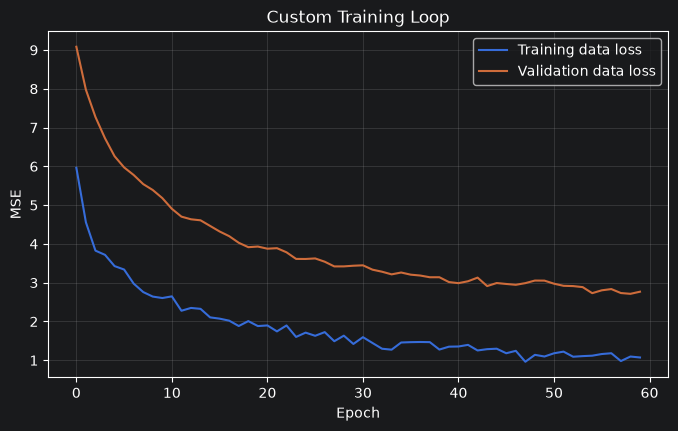

In [44]:
plt.figure(figsize=(8, 4.5))
plt.plot(custom_train_data_history, label="Training data loss")
plt.plot(custom_val_data_history, label="Validation data loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Custom Training Loop")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 12.5 Custom Loop: Important Implementation Notes

- Include `model.losses` when using Keras regularizers or layers that contribute auxiliary losses.
- Pass the correct `training` flag to the model.
- Handle metrics explicitly; Keras does not automatically populate a `History` object for a manual loop.
- Add checkpointing and early-stopping logic yourself if you need them in a custom loop.
- Use `@tf.function` after the eager implementation is correct. Eager execution is often easier to debug.

## 13. Controlled Regularization Experiment

We now compare several training strategies using the same training/validation split. The models differ in regularization, not in the underlying prediction task.

The comparison includes:

1. A high-capacity model without explicit regularization.
2. An L2-regularized model.
3. A dropout model.
4. A batch-normalized model with dropout.

A model should not be selected by whichever training curve looks best. Use validation performance, training stability, and model complexity together. The test set remains untouched until the final model has been chosen.

In [45]:
experiment_configs = {
    "Unregularized": dict(units=(128, 64), dropout_rate=0.0, l2_strength=0.0, batch_norm=False),
    "L2": dict(units=(128, 64), dropout_rate=0.0, l2_strength=1e-3, batch_norm=False),
    "Dropout": dict(units=(128, 64), dropout_rate=0.25, l2_strength=0.0, batch_norm=False),
    "BatchNorm + Dropout": dict(units=(128, 64), dropout_rate=0.20, l2_strength=0.0, batch_norm=True),
}

experiment_histories = {}
experiment_models = {}

for model_name, config in experiment_configs.items():
    keras.utils.set_random_seed(SEED)
    model = build_mlp(**config)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=100,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=12, restore_best_weights=True, min_delta=1e-4
            )
        ],
        verbose=0,
    )
    experiment_histories[model_name] = history.history
    experiment_models[model_name] = model
    print(
        f"{model_name:>22}: epochs={len(history.history['loss']):>3}, "
        f"best val MSE={min(history.history['val_loss']):.4f}"
    )

G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


         Unregularized: epochs= 81, best val MSE=1.8152
                    L2: epochs=100, best val MSE=2.1144
               Dropout: epochs= 71, best val MSE=2.2411
   BatchNorm + Dropout: epochs= 63, best val MSE=2.1517


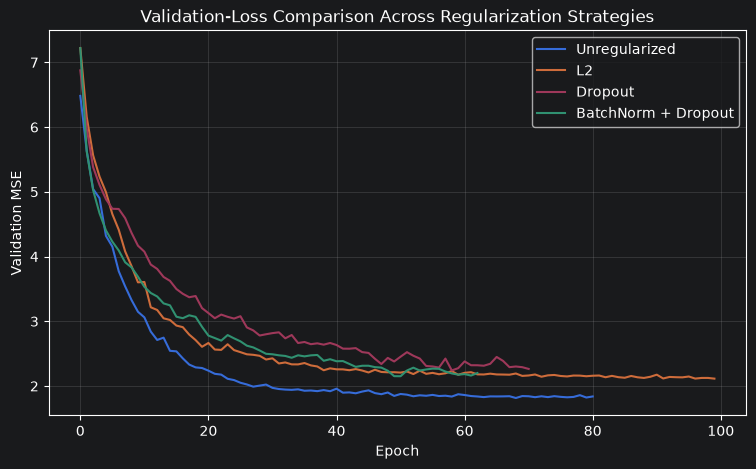

In [46]:
plt.figure(figsize=(9, 5))
for model_name, history in experiment_histories.items():
    plt.plot(history["val_loss"], label=model_name)
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Validation-Loss Comparison Across Regularization Strategies")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 13.1 Select a Candidate Using Validation Loss

For this teaching experiment, choose the model with the lowest best validation MSE. In real applications, the selection criterion should match the objective and may include multiple metrics, operational constraints, and uncertainty estimates.

In [47]:
best_model_name = min(
    experiment_histories,
    key=lambda name: min(experiment_histories[name]["val_loss"]),
)
best_candidate_model = experiment_models[best_model_name]
best_validation_mse = min(experiment_histories[best_model_name]["val_loss"])

print("Selected candidate:", best_model_name)
print("Best validation MSE:", best_validation_mse)

Selected candidate: Unregularized
Best validation MSE: 1.81521737575531


### 13.2 Final Test Evaluation

After selecting the candidate using validation data, evaluate it once on the held-out test set. Report both error metrics and the context in which they were calculated. Do not return to model selection based on this test result.

In [48]:
test_predictions = best_candidate_model.predict(X_test_scaled, verbose=0).ravel()
final_test_mse = mean_squared_error(y_test, test_predictions)
final_test_rmse = float(np.sqrt(final_test_mse))
final_test_mae = mean_absolute_error(y_test, test_predictions)
final_test_r2 = r2_score(y_test, test_predictions)

final_test_results = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R-squared"],
    "Test value": [final_test_mse, final_test_rmse, final_test_mae, final_test_r2],
})
final_test_results

,Metric,Test value
0,MSE,1.356802
1,RMSE,1.164818
2,MAE,0.881799
3,R-squared,0.746340


In [ ]:
residuals = y_test - test_predictions
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, test_predictions, alpha=0.65)
limits = [min(y_test.min(), test_predictions.min()), max(y_test.max(), test_predictions.max())]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set_xlabel("Observed target")
axes[0].set_ylabel("Predicted target")
axes[0].set_title("Observed vs. Predicted")
axes[1].scatter(test_predictions, residuals, alpha=0.65)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set_xlabel("Predicted target")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs. Predictions")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 13.3 Residual Analysis

A residual is the difference between an observed target and its prediction:

$$
e_i = y_i - \hat{y}_i
$$

Inspect residuals for:

- systematic patterns across predicted values;
- changing spread across the prediction range;
- extreme observations;
- evidence that the model misses nonlinear structure;
- possible data-quality or split-related problems.

Residual plots can reveal issues that a single aggregate metric hides. They do not, by themselves, establish that a model is unbiased or valid for a real-world application.

## 14. Common Optimization and Regularization Mistakes

1. **Using a learning rate that is too large:** training may oscillate or diverge.
2. **Using a learning rate that is too small:** apparent progress may be extremely slow.
3. **Comparing optimizers unfairly:** different splits, initial weights, or epoch budgets confound the comparison.
4. **Fitting preprocessing on all data:** this leaks information from validation or test sets into training.
5. **Using the test set for early stopping:** this turns the test set into a model-selection set.
6. **Adding too much regularization:** the model may underfit.
7. **Treating batch normalization as a universal regularizer:** its primary operation is normalization of activations; effects depend on batch and inference behavior.
8. **Forgetting `model.losses` in a custom loop:** regularization penalties may be omitted from the objective.
9. **Forgetting `training=True` in a custom training step:** dropout and batch normalization may behave as they do during inference.
10. **Assuming Adam or AdamW always wins:** optimizer performance is problem-dependent.
11. **Using clipping to hide an unstable setup:** clipping does not replace sound initialization, preprocessing, and learning-rate selection.
12. **Reporting only training loss:** generalization must be assessed on data not used to update model weights.

## Exercises

Complete these exercises after running the notebook.

### Exercise 1 — Learning-Rate Stability

Modify the one-dimensional gradient-descent example. Try at least five learning rates and explain which values converge, oscillate, or diverge.

### Exercise 2 — Optimizer Comparison

Compare SGD, SGD with momentum, RMSprop, Adam, and AdamW on the same data split and architecture. Repeat the experiment with at least three random seeds. Report mean and standard deviation of the best validation MSE.

### Exercise 3 — Initialization

Train otherwise identical networks using Glorot and He initialization. Compare convergence speed and validation performance. Explain why the activation function matters when choosing an initializer.

### Exercise 4 — L1 vs. L2

Fit models using L1 and L2 penalties. Compare training loss, validation loss, and the distribution of learned weights. Discuss whether L1 produces a sparser parameter vector in your experiment.

### Exercise 5 — Dropout Rate

Compare dropout rates of 0.0, 0.1, 0.25, and 0.5. Identify any evidence of underfitting or overfitting.

### Exercise 6 — Batch Normalization

Compare a model with and without batch normalization. Repeat with a smaller batch size and discuss changes in training stability.

### Exercise 7 — Custom Training Loop

Extend the custom loop to report RMSE and to save the best validation checkpoint. Explain which parts of `model.fit()` must be implemented manually.

### Exercise 8 — Generalization and Reporting

Write a short report comparing the unregularized and selected regularized models. Include the split protocol, model configuration, validation-based selection rule, one final test evaluation, and residual plots.

## Key Takeaways

- Neural-network training is an optimization problem: parameters are updated using gradients of a loss function.
- Backpropagation applies the chain rule to compute gradients efficiently.
- Mini-batch gradient descent is the common practical training strategy.
- Optimizers differ in how they use current and historical gradients; no optimizer is universally best.
- The learning rate and initialization strongly influence optimization stability.
- Overfitting occurs when training performance improves without corresponding validation improvement.
- L1/L2 penalties, dropout, batch normalization, and early stopping have different mechanisms and should not be treated as interchangeable.
- AdamW applies decoupled weight decay; this is not generally identical to L2 regularization with adaptive optimizers.
- Custom loops must handle regularization losses, training/inference mode, metrics, and checkpointing explicitly.
- The validation set supports model selection; the test set is reserved for final evaluation.

## References and Further Reading

1. TensorFlow — [Writing a training loop from scratch](https://www.tensorflow.org/guide/keras/writing_a_training_loop_from_scratch)
2. TensorFlow — [Effective TensorFlow 2](https://www.tensorflow.org/guide/effective_tf2)
3. TensorFlow — [Custom training walkthrough](https://www.tensorflow.org/tutorials/customization/custom_training_walkthrough)
4. Keras — [Optimizers API](https://keras.io/api/optimizers/)
5. Keras — [Callbacks API](https://keras.io/api/callbacks/)
6. Keras — [Layer weight regularizers](https://keras.io/api/layers/regularizers/)
7. Keras — [Writing a custom training loop in TensorFlow](https://keras.io/guides/writing_a_custom_training_loop_in_tensorflow/)
8. Goodfellow, Bengio, and Courville — *Deep Learning*, MIT Press, 2016. [Online book](https://www.deeplearningbook.org/)

Use the official API documentation matching your installed TensorFlow/Keras version when adapting code to a different environment.

## Completion Checklist

Before moving to Notebook 08, make sure you can:

- [ ] Explain how gradients are computed and used to update parameters.
- [ ] Verify a small analytical gradient using finite differences.
- [ ] Compare batch, stochastic, and mini-batch gradient descent.
- [ ] Explain the practical differences among SGD, Momentum, RMSprop, Adam, and AdamW.
- [ ] Recognize unstable learning-rate behavior.
- [ ] Explain initialization and gradient-flow problems.
- [ ] Diagnose overfitting from training and validation curves.
- [ ] Apply at least two regularization strategies and compare them fairly.
- [ ] Use early stopping and save a best-validation checkpoint.
- [ ] Implement a custom loop that includes `model.losses` and correct training/inference behavior.
- [ ] Evaluate the selected model on the test set only after model selection is complete.